# RotaLivre — Modelo de Classificação de Acessibilidade

Este notebook desenvolve um modelo de Machine Learning para classificar locais urbanos em três categorias:

- ACESSIVEL
- PARCIAL
- INACESSIVEL

O modelo utiliza características físicas e recursos de acessibilidade dos locais.

**Algoritmo:** Random Forest Classifier.

**Importante:** nesta etapa, utilizamos uma base sintética de 600 registros, identificados pela coluna `origem_dados`. Portanto, os resultados representam experimentos com dados simulados e não comprovam a capacidade de avaliar a acessibilidade de locais reais.

In [16]:
# Bibliotecas para manipulação e análise dos dados
import pandas as pd
import numpy as np

# Bibliotecas para separar os dados e construir o modelo
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Algoritmos de Machine Learning
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier

# Métricas para avaliar o modelo
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Ferramentas para visualizar gráficos
import matplotlib.pyplot as plt
import seaborn as sns

# Bibliotecas para exportar o modelo e seus dados
import joblib
import json
from pathlib import Path

sns.set_theme(style="whitegrid")

print("Bibliotecas importadas com sucesso!")

Bibliotecas importadas com sucesso!


In [17]:
# Identifica a pasta principal do projeto
raiz_projeto = Path.cwd()

# Se o notebook estiver sendo executado dentro de notebooks,
# volta um nível para encontrar a raiz do projeto
if raiz_projeto.name == "notebooks":
    raiz_projeto = raiz_projeto.parent

# Define o caminho do arquivo CSV
caminho_csv = raiz_projeto / "dados" / "locais_acessibilidade.csv"

# Verifica se o arquivo existe antes de carregar
if not caminho_csv.exists():
    raise FileNotFoundError(f"Arquivo não encontrado: {caminho_csv}")

# Carrega os dados
df = pd.read_csv(caminho_csv)

print("Base carregada com sucesso!")
print(f"Quantidade de registros: {len(df)}")
print(f"Quantidade de colunas: {len(df.columns)}")

df.head()

Base carregada com sucesso!
Quantidade de registros: 600
Quantidade de colunas: 15


,id_local,tipo_local,largura_calcada_m,inclinacao_graus,rampa,piso_tatil,piso_regular,sinalizacao_acessivel,quantidade_relatos,usuarios_distintos,nota_acessibilidade,situacao_acessibilidade,latitude,longitude,origem_dados
0,1,ESTABELECIMENTO,2.40,13.18,0,0,0,1,2,2,52,PARCIAL,-23.529384,-46.654258,SINTETICO_SIMULADO
1,2,ELEVADOR,0.49,17.46,1,1,1,1,15,11,52,PARCIAL,-23.585950,-46.609499,SINTETICO_SIMULADO
2,3,CALCADA,1.53,7.20,1,1,1,1,14,13,86,ACESSIVEL,-23.575230,-46.618999,SINTETICO_SIMULADO
3,4,CALCADA,0.55,10.94,0,0,0,1,3,0,35,INACESSIVEL,-23.576061,-46.613433,SINTETICO_SIMULADO
4,5,RAMPA,1.85,7.92,0,1,0,1,14,2,65,PARCIAL,-23.532210,-46.623183,SINTETICO_SIMULADO


In [18]:
# Verifica a distribuição das classificações
print("Distribuição das classificações:")
print(df["situacao_acessibilidade"].value_counts())

print("\nOrigem dos dados:")
print(df["origem_dados"].value_counts())

# Verifica se existem valores ausentes
print("\nValores ausentes:")
print(df.isnull().sum())

Distribuição das classificações:
situacao_acessibilidade
PARCIAL        365
ACESSIVEL      138
INACESSIVEL     97
Name: count, dtype: int64

Origem dos dados:
origem_dados
SINTETICO_SIMULADO    600
Name: count, dtype: int64

Valores ausentes:
id_local                   0
tipo_local                 0
largura_calcada_m          0
inclinacao_graus           0
rampa                      0
piso_tatil                 0
piso_regular               0
sinalizacao_acessivel      0
quantidade_relatos         0
usuarios_distintos         0
nota_acessibilidade        0
situacao_acessibilidade    0
latitude                   0
longitude                  0
origem_dados               0
dtype: int64


In [19]:
# Variáveis que serão utilizadas para realizar as previsões
colunas_categoricas = [
    "tipo_local"
]

colunas_numericas = [
    "largura_calcada_m",
    "inclinacao_graus",
    "rampa",
    "piso_tatil",
    "piso_regular",
    "sinalizacao_acessivel",
    "quantidade_relatos",
    "usuarios_distintos"
]

# Junta todas as variáveis de entrada
colunas_entrada = colunas_categoricas + colunas_numericas

# Define a variável que queremos prever
coluna_alvo = "situacao_acessibilidade"

# Separa as entradas e as respostas
X = df[colunas_entrada].copy()
y = df[coluna_alvo].copy()

# Confere as informações
print("Variáveis utilizadas:")
print(colunas_entrada)

print("\nClasses que o modelo deverá prever:")
print(sorted(y.unique()))

print("\nQuantidade de entradas:", X.shape[1])
print("Quantidade de registros:", X.shape[0])

Variáveis utilizadas:
['tipo_local', 'largura_calcada_m', 'inclinacao_graus', 'rampa', 'piso_tatil', 'piso_regular', 'sinalizacao_acessivel', 'quantidade_relatos', 'usuarios_distintos']

Classes que o modelo deverá prever:
['ACESSIVEL', 'INACESSIVEL', 'PARCIAL']

Quantidade de entradas: 9
Quantidade de registros: 600


In [20]:
# Separa 80% dos registros para treinamento e 20% para teste.
# stratify mantém aproximadamente a mesma proporção de classes
# nos dois conjuntos.
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Separação realizada com sucesso!")

print(f"Registros para treinamento: {len(X_treino)}")
print(f"Registros para teste: {len(X_teste)}")

print("\nDistribuição das classes no treinamento:")
print(y_treino.value_counts(normalize=True).round(3))

print("\nDistribuição das classes no teste:")
print(y_teste.value_counts(normalize=True).round(3))

Separação realizada com sucesso!
Registros para treinamento: 480
Registros para teste: 120

Distribuição das classes no treinamento:
situacao_acessibilidade
PARCIAL        0.608
ACESSIVEL      0.229
INACESSIVEL    0.162
Name: proportion, dtype: float64

Distribuição das classes no teste:
situacao_acessibilidade
PARCIAL        0.608
ACESSIVEL      0.233
INACESSIVEL    0.158
Name: proportion, dtype: float64


In [21]:
# Para os dados categóricos, substitui valores ausentes
# pela categoria mais frequente e transforma os textos em números.
preprocessamento_categorico = Pipeline(steps=[
    ("imputacao", SimpleImputer(strategy="most_frequent")),
    ("codificacao", OneHotEncoder(handle_unknown="ignore"))
])

# Para os dados numéricos, substitui valores ausentes pela mediana.
preprocessamento_numerico = Pipeline(steps=[
    ("imputacao", SimpleImputer(strategy="median"))
])

# Junta os dois tipos de preparação.
preprocessamento = ColumnTransformer(transformers=[
    ("categoricas", preprocessamento_categorico, colunas_categoricas),
    ("numericas", preprocessamento_numerico, colunas_numericas)
])

# Cria o algoritmo Random Forest.
# Ele combina várias árvores de decisão para realizar a classificação.
classificador = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

# Cria um pipeline que executa a preparação e a classificação.
modelo = Pipeline(steps=[
    ("preprocessamento", preprocessamento),
    ("classificador", classificador)
])

print("Pipeline do modelo criado com sucesso!")

Pipeline do modelo criado com sucesso!


In [22]:
# O modelo aprende padrões a partir dos dados de treinamento.
modelo.fit(X_treino, y_treino)

print("Treinamento concluído com sucesso!")

Treinamento concluído com sucesso!


In [23]:
# Realiza previsões utilizando os dados que não participaram do treinamento.
y_predito = modelo.predict(X_teste)

# Cria um modelo de referência que sempre prevê a classe mais frequente.
# Ele ajuda a verificar se o Random Forest apresenta algum ganho.
modelo_referencia = DummyClassifier(strategy="most_frequent")
modelo_referencia.fit(X_treino, y_treino)

y_referencia = modelo_referencia.predict(X_teste)

# Calcula as métricas do Random Forest.
acuracia = accuracy_score(y_teste, y_predito)
precisao = precision_score(y_teste, y_predito, average="macro", zero_division=0)
revocacao = recall_score(y_teste, y_predito, average="macro", zero_division=0)
f1 = f1_score(y_teste, y_predito, average="macro", zero_division=0)

# Calcula a acurácia do modelo de referência.
acuracia_referencia = accuracy_score(y_teste, y_referencia)

print("RESULTADOS DO RANDOM FOREST")
print(f"Acurácia:  {acuracia:.4f}")
print(f"Precisão:  {precisao:.4f}")
print(f"Recall:    {revocacao:.4f}")
print(f"F1-score:  {f1:.4f}")

print("\nMODELO DE REFERÊNCIA")
print(f"Acurácia: {acuracia_referencia:.4f}")

RESULTADOS DO RANDOM FOREST
Acurácia:  0.8083
Precisão:  0.7797
Recall:    0.8250
F1-score:  0.7990

MODELO DE REFERÊNCIA
Acurácia: 0.6083


In [24]:
# Apresenta as métricas detalhadas para cada classe.
print("Relatório de classificação:")
print(
    classification_report(
        y_teste,
        y_predito,
        zero_division=0
    )
)

Relatório de classificação:
              precision    recall  f1-score   support

   ACESSIVEL       0.69      0.79      0.73        28
 INACESSIVEL       0.77      0.89      0.83        19
     PARCIAL       0.88      0.79      0.83        73

    accuracy                           0.81       120
   macro avg       0.78      0.82      0.80       120
weighted avg       0.82      0.81      0.81       120



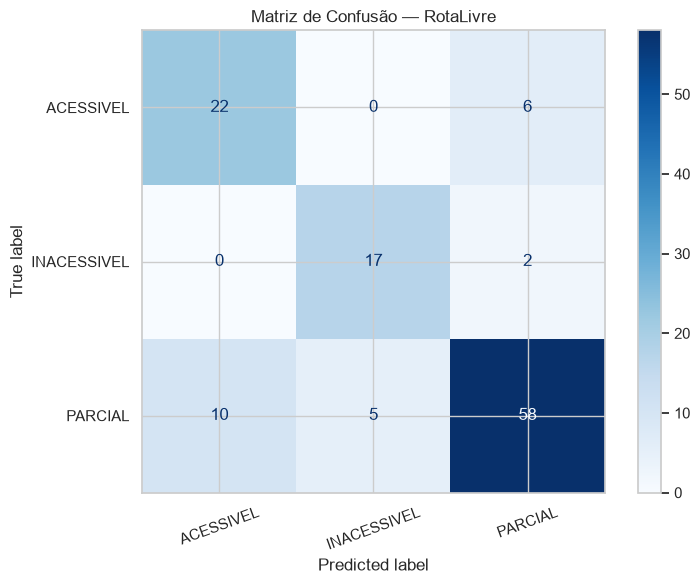

In [25]:
# A matriz mostra quantas previsões foram corretas
# e quantas foram confundidas com outras categorias.
matriz = confusion_matrix(
    y_teste,
    y_predito,
    labels=modelo.classes_
)

visualizacao = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=modelo.classes_
)

fig, ax = plt.subplots(figsize=(8, 6))
visualizacao.plot(
    cmap="Blues",
    values_format="d",
    ax=ax
)

plt.title("Matriz de Confusão — RotaLivre")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

Importância das variáveis:


,variavel,importancia
5,numericas__largura_calcada_m,0.302492
6,numericas__inclinacao_graus,0.206247
11,numericas__quantidade_relatos,0.078595
8,numericas__piso_tatil,0.073025
12,numericas__usuarios_distintos,0.067892
9,numericas__piso_regular,0.067657
7,numericas__rampa,0.066305
10,numericas__sinalizacao_acessivel,0.062861
1,categoricas__tipo_local_ELEVADOR,0.016738
0,categoricas__tipo_local_CALCADA,0.016518


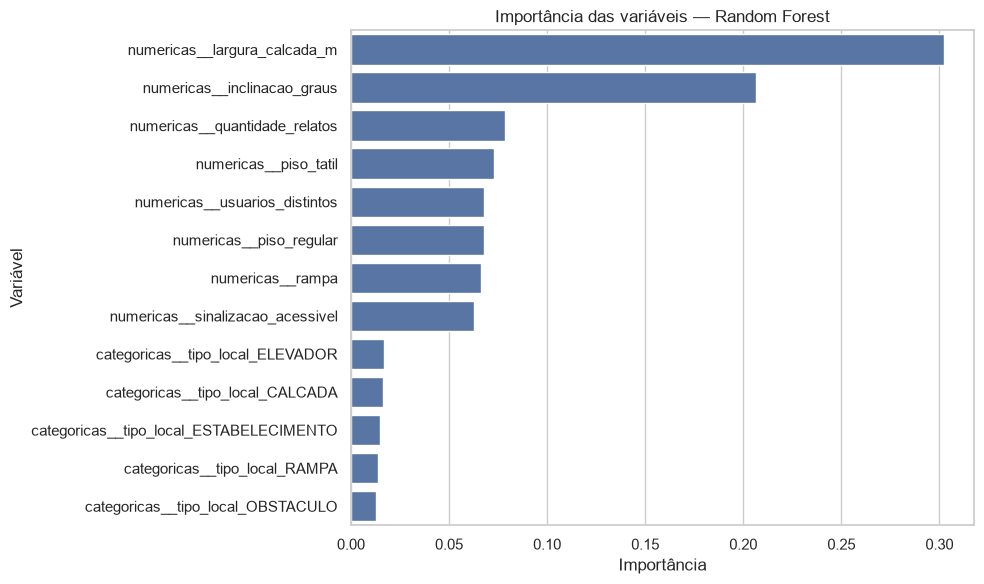

In [26]:
# Recupera o classificador treinado dentro do pipeline.
classificador_treinado = modelo.named_steps["classificador"]

# Recupera os nomes das variáveis após a preparação.
nomes_variaveis = (
    modelo.named_steps["preprocessamento"].get_feature_names_out()
)

# Organiza a importância de cada variável.
importancias = pd.DataFrame({
    "variavel": nomes_variaveis,
    "importancia": classificador_treinado.feature_importances_
})

# Ordena da variável mais importante para a menos importante.
importancias = importancias.sort_values(
    by="importancia",
    ascending=False
)

print("Importância das variáveis:")
display(importancias)

# Cria um gráfico para facilitar a interpretação.
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importancias,
    x="importancia",
    y="variavel"
)

plt.title("Importância das variáveis — Random Forest")
plt.xlabel("Importância")
plt.ylabel("Variável")
plt.tight_layout()
plt.show()

In [27]:
# Seleciona um registro do conjunto de teste para demonstrar
# como o modelo realiza uma classificação.
exemplo = X_teste.iloc[[0]]

# Realiza a previsão.
previsao = modelo.predict(exemplo)[0]

print("CARACTERÍSTICAS DO LOCAL:")
display(exemplo)

print("\nCLASSIFICAÇÃO PREVISTA PELO MODELO:")
print(previsao)

print("\nCLASSIFICAÇÃO ORIGINAL DA BASE:")
print(y_teste.iloc[0])

CARACTERÍSTICAS DO LOCAL:


,tipo_local,largura_calcada_m,inclinacao_graus,rampa,piso_tatil,piso_regular,sinalizacao_acessivel,quantidade_relatos,usuarios_distintos
322,OBSTACULO,0.79,0.04,1,0,1,1,1,1



CLASSIFICAÇÃO PREVISTA PELO MODELO:
PARCIAL

CLASSIFICAÇÃO ORIGINAL DA BASE:
PARCIAL


In [28]:
from pathlib import Path

# Localiza a pasta principal do projeto.
raiz_projeto = Path.cwd()

# Se o notebook estiver sendo executado dentro de notebooks/,
# volta uma pasta para chegar à raiz do projeto.
if raiz_projeto.name == "notebooks":
    raiz_projeto = raiz_projeto.parent

print("Pasta do projeto:", raiz_projeto)
print("Pasta de modelos:", raiz_projeto / "modelos")

Pasta do projeto: c:\Users\usuario\Desktop\fiap-2sem\gs\RotaLivre-IA
Pasta de modelos: c:\Users\usuario\Desktop\fiap-2sem\gs\RotaLivre-IA\modelos


In [29]:
import joblib
import json

# Salva o modelo treinado para a API Flask utilizar.
pasta_modelos = raiz_projeto / "modelos"
pasta_modelos.mkdir(parents=True, exist_ok=True)

caminho_modelo = pasta_modelos / "modelo_classificacao.joblib"

joblib.dump(modelo, caminho_modelo)

print("Modelo salvo em:", caminho_modelo)
print("Tamanho do arquivo:", caminho_modelo.stat().st_size, "bytes")

Modelo salvo em: c:\Users\usuario\Desktop\fiap-2sem\gs\RotaLivre-IA\modelos\modelo_classificacao.joblib
Tamanho do arquivo: 3810611 bytes


In [30]:
# Define a pasta onde os modelos serão armazenados.
pasta_modelos = raiz_projeto / "modelos"

# Cria a pasta caso ainda não exista.
pasta_modelos.mkdir(parents=True, exist_ok=True)

# Define o caminho do arquivo do modelo.
caminho_modelo = pasta_modelos / "modelo_classificacao.joblib"

# Exporta o pipeline completo, incluindo o pré-processamento.
joblib.dump(modelo, caminho_modelo)

# Cria um arquivo com informações importantes sobre o modelo.
metadados = {
    "nome": "Modelo de Classificacao RotaLivre",
    "algoritmo": "RandomForestClassifier",
    "variavel_alvo": coluna_alvo,
    "variaveis_entrada": colunas_entrada,
    "classes": [str(classe) for classe in modelo.classes_],
    "quantidade_registros": int(len(df)),
    "origem_dados": "SINTETICO_SIMULADO",
    "metricas": {
        "acuracia": float(acuracia),
        "precisao_macro": float(precisao),
        "recall_macro": float(revocacao),
        "f1_macro": float(f1)
    },
    "observacao": (
        "Resultados experimentais obtidos com dados sintéticos. "
        "Nao representam validacao de acessibilidade em locais reais."
    )
}

caminho_metadados = pasta_modelos / "metadata_classificacao.json"

with open(caminho_metadados, "w", encoding="utf-8") as arquivo:
    json.dump(metadados, arquivo, indent=4, ensure_ascii=False)

print("Modelo exportado com sucesso!")
print(f"Modelo: {caminho_modelo}")
print(f"Metadados: {caminho_metadados}")

Modelo exportado com sucesso!
Modelo: c:\Users\usuario\Desktop\fiap-2sem\gs\RotaLivre-IA\modelos\modelo_classificacao.joblib
Metadados: c:\Users\usuario\Desktop\fiap-2sem\gs\RotaLivre-IA\modelos\metadata_classificacao.json


## Conclusão

Neste notebook foi desenvolvido um modelo de classificação utilizando Random Forest.

O processo incluiu:

- Seleção das variáveis de entrada.
- Separação dos dados em treinamento e teste.
- Preparação das variáveis categóricas e numéricas.
- Treinamento do algoritmo.
- Avaliação por acurácia, precisão, recall e F1-score.
- Análise da matriz de confusão.
- Verificação da importância das variáveis.
- Exportação do modelo no formato JOBLIB.

**Limitação:** os dados utilizados são sintéticos e as classificações foram produzidas por regras simuladas. Portanto, as métricas não devem ser interpretadas como desempenho comprovado em locais reais.

Quando a base oficial do projeto estiver disponível, será necessário substituir ou complementar os dados e realizar uma nova avaliação.